# Local polynomial regression

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.nonparametric.kernel_regression import KernelReg
from statsmodels.nonparametric.smoothers_lowess import lowess
from ipywidgets import interact, FloatSlider, IntSlider

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
true_color  = '#333333'
local_color = '#E69F00'

To estimate the regression function at a point $x_0$, we fit a polynomial of degree $d$ by weighted least squares, giving more weight to the observations close to $x_0$,
$$\hat\beta(x_0) = (X_{x_0}^TW_{x_0}X_{x_0})^{-1}X_{x_0}^TW_{x_0}Y, \qquad \hat m(x_0) = e_1^T\hat\beta(x_0),$$
where $X_{x_0}$ has the columns $1, (x_i-x_0), \ldots, (x_i-x_0)^d$ and $W_{x_0}$ is diagonal with the weights $K\left(\frac{x_i-x_0}{h}\right)$. The kernel $K$ gives the shape of the weights and the bandwidth $h$ how local the fit is.

## The data

In [3]:
def m(x):
    return (np.sin(2*np.pi*x**3))**3

In [4]:
rng = np.random.default_rng(111)

n = 100
x = rng.uniform(size=n)
Y = m(x) + rng.normal(scale=0.1, size=n)

x_grid = np.linspace(0, 1, 300)
m_grid = m(x_grid)

In [5]:
def plot_data(ax, legend=True):
    ax.plot(x_grid, m_grid, '--', color=true_color, lw=1.5, label='Regression function')
    ax.plot(x, Y, 'o', color=point_color, markersize=6, markeredgecolor='white', markeredgewidth=0.5,
            label='Observed data')
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_ylim(-1.5, 1.9)
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper center', ncol=4, frameon=False)

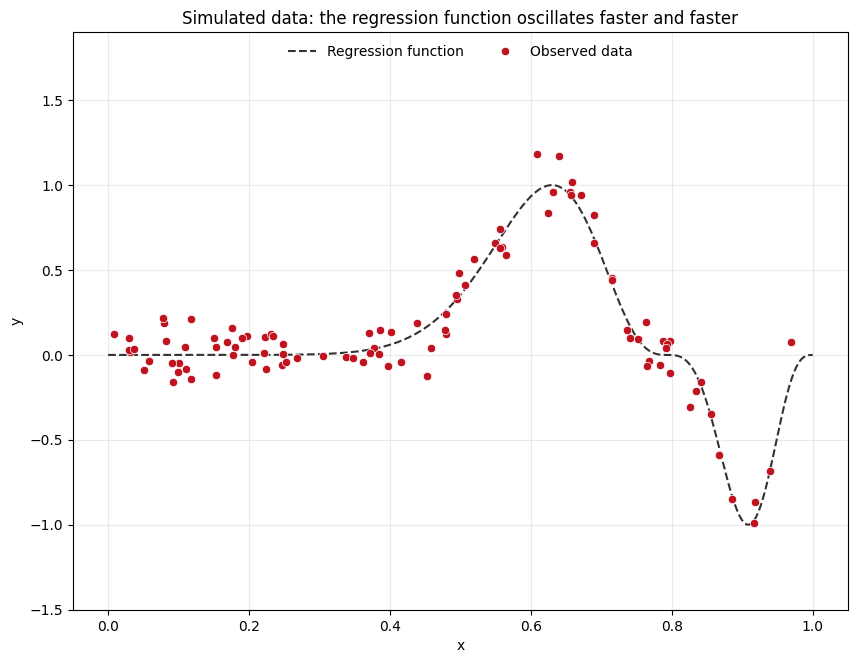

In [6]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_data(ax)
ax.set_title('Simulated data: the regression function oscillates faster and faster');

## Local polynomial regression by hand

In [7]:
def gaussian(u):
    return norm.pdf(u)

def epanechnikov(u):
    return 0.75*np.clip(1-u**2, 0, None)

def tricube(u):
    return np.clip(1-np.abs(u)**3, 0, None)**3

In [8]:
def local_poly(x0, x, Y, h, degree=1, kernel=gaussian):
    # Coefficients of the polynomial fitted around x0, the first one is the estimate of m(x0)
    X = np.vstack([(x-x0)**d for d in range(degree+1)]).T
    w = kernel((x-x0)/h)
    WX = X*w[:, None]
    return np.linalg.solve(X.T @ WX, WX.T @ Y)

def hat_m(x_grid, x, Y, h, degree=1, kernel=gaussian):
    return np.array([local_poly(x0, x, Y, h, degree, kernel)[0] for x0 in x_grid])

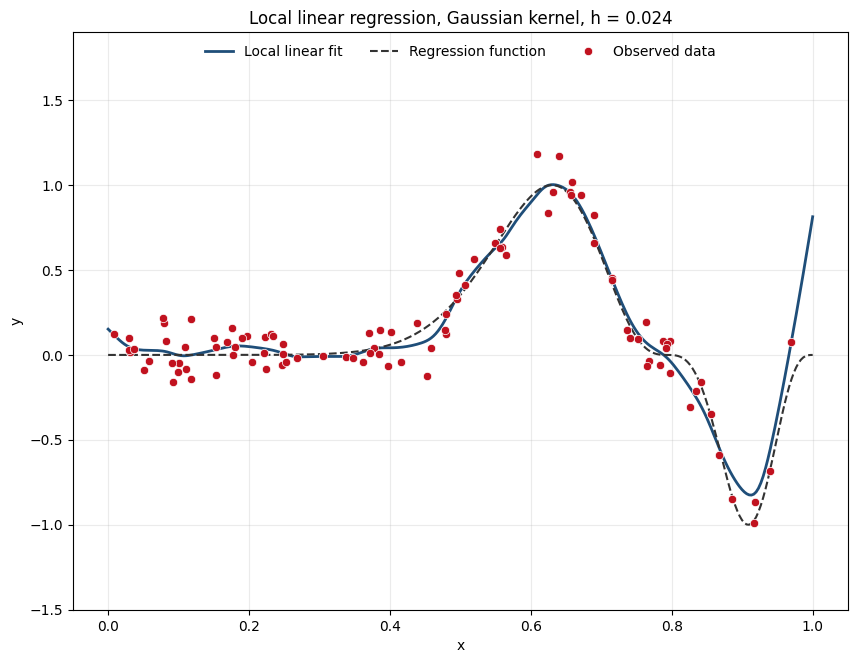

In [9]:
h = 0.024
m_grid_hat = hat_m(x_grid, x, Y, h)

fig, ax = plt.subplots(figsize=(10, 7.5))
ax.plot(x_grid, m_grid_hat, color=line_color, lw=2, label='Local linear fit')
plot_data(ax)
ax.set_title(f'Local linear regression, Gaussian kernel, h = {h}');

### What happens at each point

For three values of $x_0$: the size of the points is their weight, the orange line is the local line fitted with those weights, and the fit at $x_0$ is the value of that line there.

In [10]:
def plot_local_fit(ax, x0, h, degree=1, legend=True):
    w = gaussian((x-x0)/h)
    w = w/w.max()
    beta = local_poly(x0, x, Y, h, degree)
    x_local = np.linspace(x0-2.5*h, x0+2.5*h, 50)
    Y_local = sum(beta[d]*(x_local-x0)**d for d in range(degree+1))

    ax.axvspan(x0-2*h, x0+2*h, color='#cfe8f3', alpha=0.6, label=r'$x_0 \pm 2h$')
    ax.plot(x_grid, m_grid, '--', color=true_color, lw=1.5, label='Regression function')
    ax.plot(x_grid, hat_m(x_grid, x, Y, h, degree), color=line_color, lw=1.5, alpha=0.5, label='Fit')
    ax.scatter(x, Y, s=8 + 110*w, color=point_color, alpha=0.25 + 0.75*w, edgecolor='white', linewidth=0.5,
               label='Observed data (size: weight)', zorder=3)
    ax.plot(x_local, Y_local, color=local_color, lw=3, label='Local polynomial', zorder=4)
    ax.plot(x0, beta[0], 'o', color=local_color, markersize=11, markeredgecolor=true_color, markeredgewidth=1.5,
            label=r'$\hat m(x_0)$', zorder=5)
    ax.set_xlabel('x')
    ax.set_ylim(-1.5, 1.9)
    ax.set_title(f'$x_0$ = {x0:.2f}')
    ax.grid(True, alpha=0.25)

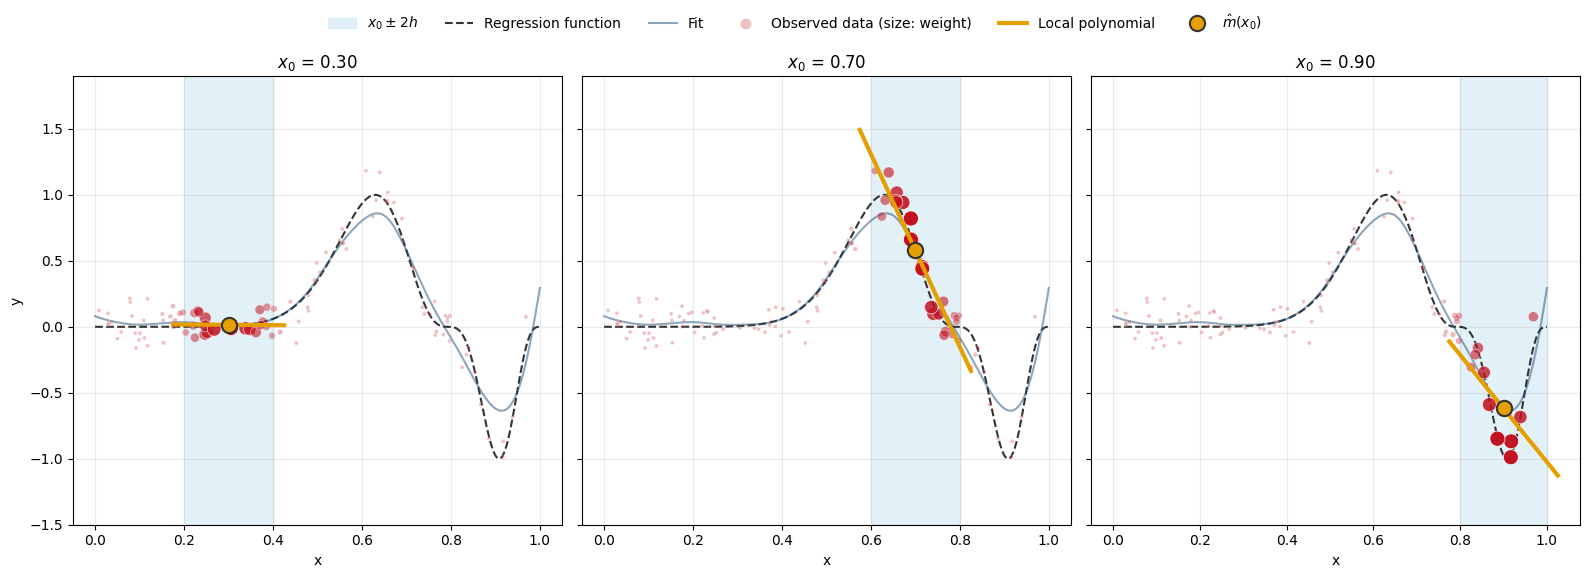

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharey=True)
for ax, x0 in zip(axes, [0.3, 0.7, 0.9]):
    plot_local_fit(ax, x0, h=0.05)
axes[0].set_ylabel('y')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=6, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))

### The bandwidth

With a small bandwidth the fit follows the noise, with a large one it cannot follow the regression function where it changes fast. Move the sliders to change the bandwidth, the degree and the point $x_0$ (this cell needs a running kernel).

In [ ]:
def interactive_local(h, degree, x0):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_local_fit(ax, x0, h, degree)
    ax.set_ylabel('y')
    ax.set_title(f'h = {h:.3f}, degree = {degree}, $x_0$ = {x0:.2f}')
    ax.legend(loc='upper center', ncol=3, frameon=False)
    plt.show()

interact(interactive_local,
         h=FloatSlider(value=0.024, min=0.008, max=0.2, step=0.002, readout_format='.3f', description='h'),
         degree=IntSlider(value=1, min=0, max=2, description='degree'),
         x0=FloatSlider(value=0.7, min=0.05, max=0.95, step=0.01, description='x0'));

interactive(children=(FloatSlider(value=0.024, description='h', max=0.2, min=0.008, readout_format='.3f', step…

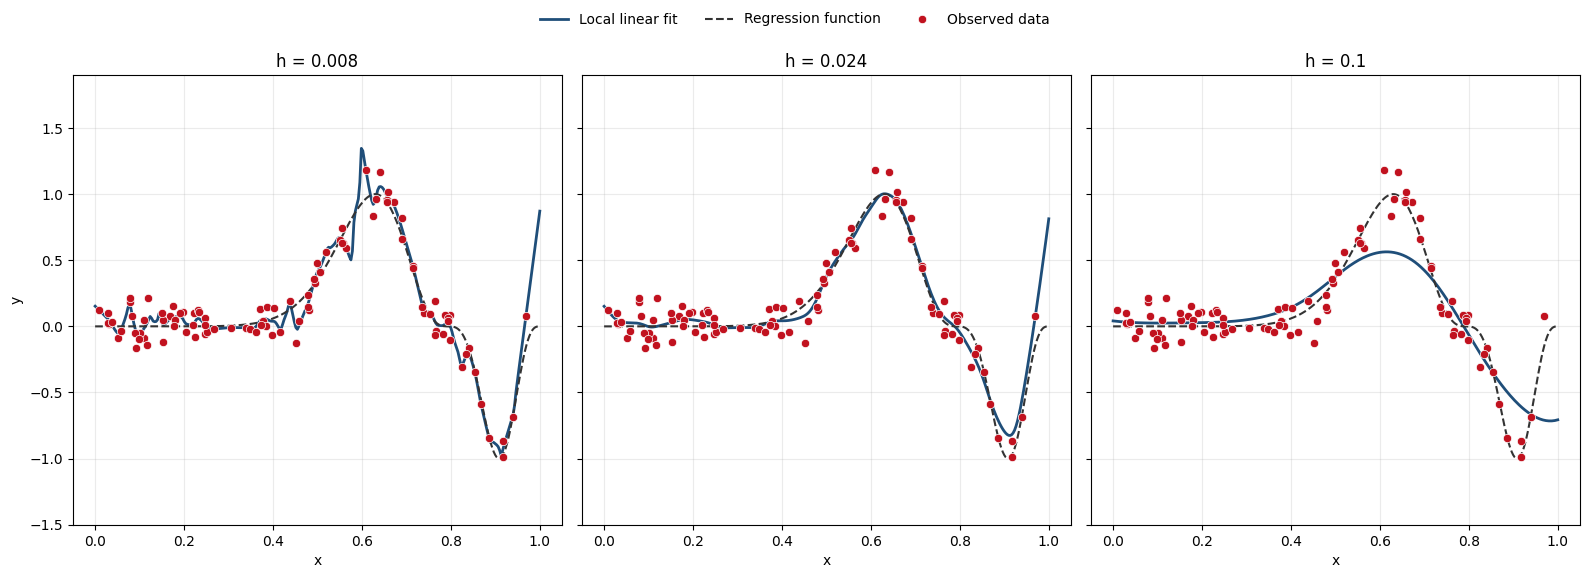

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.8), sharey=True)
for ax, h_i in zip(axes, [0.008, 0.024, 0.1]):
    ax.plot(x_grid, hat_m(x_grid, x, Y, h_i), color=line_color, lw=2, label='Local linear fit')
    plot_data(ax, legend=False)
    ax.set_title(f'h = {h_i}')
for ax in axes[1:]:
    ax.set_ylabel('')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))

## Using statsmodels

`KernelReg` with `reg_type='ll'` is the local linear estimator with Gaussian kernel, it gives the same fit.

In [14]:
kernel_reg = KernelReg(Y, x, var_type='c', reg_type='ll', bw=[h])
m_grid_hat_sm = kernel_reg.fit(x_grid)[0]

print('Largest difference with the fit by hand:', np.max(np.abs(m_grid_hat_sm - m_grid_hat)))

Largest difference with the fit by hand: 2.220446049250313e-15


## The degree of the polynomial

A second example, with 2000 observations of $\sin(x^2)$ plus noise. We compare the moving average (degree 0, Epanechnikov kernel), the local linear and the local quadratic regression (tricube kernel), all with bandwidth 0.3. These kernels are zero outside $[-1, 1]$, so only the observations at distance less than $h$ are used.

In [15]:
rng = np.random.default_rng(1234)

x_2 = np.linspace(1.5, 5, 2000)
m_2 = np.sin(x_2**2)
Y_2 = m_2 + 0.5*rng.normal(size=len(x_2))

Y_hat_0 = hat_m(x_2, x_2, Y_2, h=0.3, degree=0, kernel=epanechnikov)
Y_hat_1 = hat_m(x_2, x_2, Y_2, h=0.3, degree=1, kernel=tricube)
Y_hat_2 = hat_m(x_2, x_2, Y_2, h=0.3, degree=2, kernel=tricube)

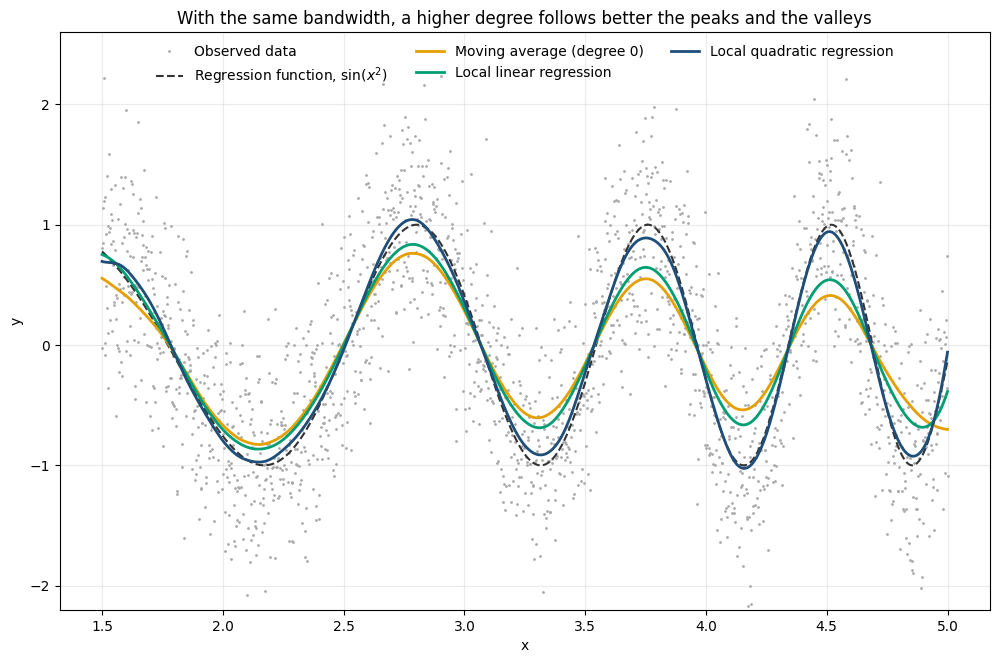

In [16]:
fig, ax = plt.subplots(figsize=(12, 7.5))
ax.plot(x_2, Y_2, '.', markersize=2, color='#aaaaaa', label='Observed data')
ax.plot(x_2, m_2, '--', color=true_color, lw=1.5, label=r'Regression function, $\sin(x^2)$')
ax.plot(x_2, Y_hat_0, color='#E69F00', lw=2, label='Moving average (degree 0)')
ax.plot(x_2, Y_hat_1, color='#009E73', lw=2, label='Local linear regression')
ax.plot(x_2, Y_hat_2, color=line_color, lw=2, label='Local quadratic regression')
ax.set_ylim(-2.2, 2.6)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('With the same bandwidth, a higher degree follows better the peaks and the valleys')
ax.legend(loc='upper center', ncol=3, frameon=False)
ax.grid(True, alpha=0.25)

The bias of each estimator, the difference between the fit and the regression function, shows it more clearly.

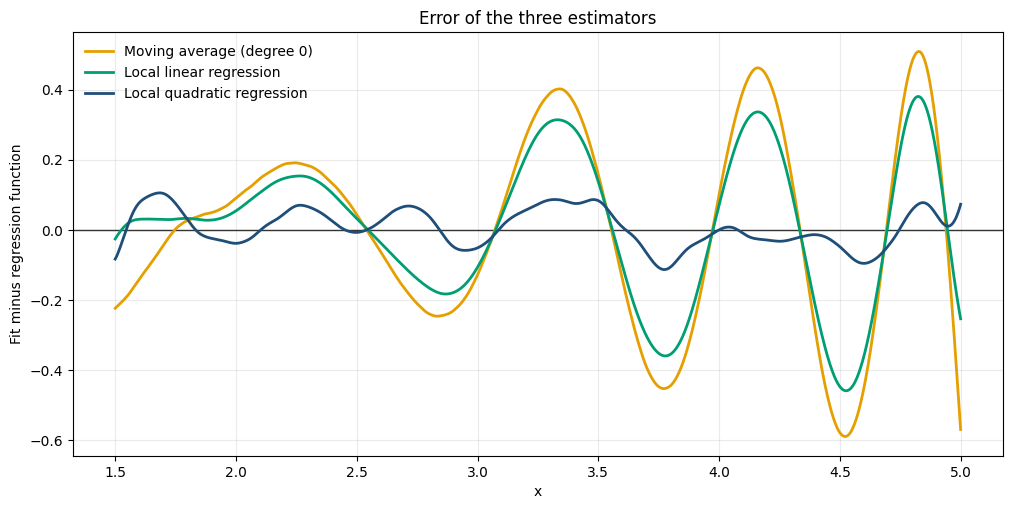

In [17]:
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.axhline(0, color=true_color, lw=1)
ax.plot(x_2, Y_hat_0-m_2, color='#E69F00', lw=2, label='Moving average (degree 0)')
ax.plot(x_2, Y_hat_1-m_2, color='#009E73', lw=2, label='Local linear regression')
ax.plot(x_2, Y_hat_2-m_2, color=line_color, lw=2, label='Local quadratic regression')
ax.set_xlabel('x')
ax.set_ylabel('Fit minus regression function')
ax.set_title('Error of the three estimators')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

`lowess`, from `statsmodels`, is a local linear regression with tricube kernel where the bandwidth is not fixed: at each point it uses the fraction `frac` of the observations closest to it.

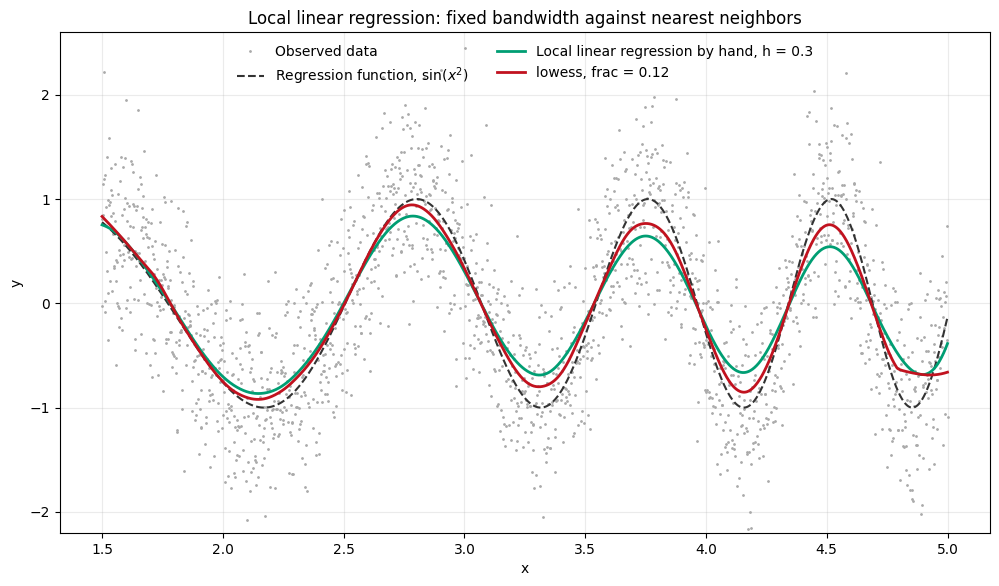

In [18]:
Y_lowess = lowess(Y_2, x_2, frac=0.12, it=0, return_sorted=False)

fig, ax = plt.subplots(figsize=(12, 6.5))
ax.plot(x_2, Y_2, '.', markersize=2, color='#aaaaaa', label='Observed data')
ax.plot(x_2, m_2, '--', color=true_color, lw=1.5, label=r'Regression function, $\sin(x^2)$')
ax.plot(x_2, Y_hat_1, color='#009E73', lw=2, label='Local linear regression by hand, h = 0.3')
ax.plot(x_2, Y_lowess, color=point_color, lw=2, label='lowess, frac = 0.12')
ax.set_ylim(-2.2, 2.6)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title('Local linear regression: fixed bandwidth against nearest neighbors')
ax.legend(loc='upper center', ncol=2, frameon=False)
ax.grid(True, alpha=0.25)